# Malaria Detection -  Milestone 3
# Part 6 - Model Improvement - Transfer Learning with EfficientNetB7

The objective of this project is to develop an efficient computer vision model to detect malaria and classify red blood cell images as parasitized or uninfected.

In Part 6 of this program, we explore transfer learning with EfficientNetB7.

This network is trained with imagenet dataset and is imported 'topless' and augmented with Dense classification layers.  The final architecture is trained with RMSprop optimizer and a very low learning rate. This yields the best performing model of the project.

Unfortunately, the model cannot be saved to disk after more than 7 hours of training on a TPU, High-RAM runtime system. This problem would have to be resolved for deployment as part of a classification system.


# Initializations & Definitions


#### Import libraries and set parameters for run time control

In [ ]:
# Reading the training dataset
from google.colab import drive
drive.mount('/content/drive')
myDataPath = "/content/drive/My Drive/Malaria/cell_images/"
myModelsPath = "/content/drive/My Drive/Malaria/Models/"

myTrainPath = myDataPath + 'train'
myTestPath = myDataPath + 'test'

# Import all needed libraries here
#!pip install keras-metrics #used for F1 score
!pip install -U seaborn-image
import warnings
warnings.filterwarnings("ignore")

import cv2
from cv2 import equalizeHist
from google.colab.patches import cv2_imshow
import keras.metrics as km
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt #plotting
import matplotlib.patches as patches
import seaborn_image as isns
import seaborn as sns
from tqdm import tqdm #progress bar
from glob import glob #finds files matching regex
import os,imageio,time #for IO, resizing and runtime profiling
from skimage import img_as_ubyte
from skimage.transform import resize
import imageio.v3 as iio
import random as rn
import math

import tensorflow as tf
import keras
from keras.applications.imagenet_utils import preprocess_input
from keras.models import Sequential
from keras.layers import Dense, Dropout, Flatten, BatchNormalization, Activation
from keras.layers import Conv2D, MaxPool2D


Mounted at /content/drive
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 332.3/332.3 kB 10.0 MB/s eta 0:00:00


### Set runtime parameters

In [ ]:
SAVE_MODEL = True

IMAGE_ENHANCEMENT = False
GAMMA = False
CONTRASTS = False

SAVE_TIME = True

###Download and Preprocess Data

***Creating Training, Validation and Test Datasets***

We will hold-out a validation set from the training set. The remaining training set can be used for hyperparameter optimization and tuning the models. The validation set can be used to test the models. The model with the best performance on the validation set will be selected. Then that model will be retrained with the entire training set (including the hold-out validation set).

***Preprocessing***

* The images are resized to a standard size which is set as a parameter in the `keras.utils.image_dataset_from_directory()` call.
* The scaling of the images is handled in a layer that is incorporated into the model: `tf.keras.layers.Rescaling(1./255)`

In [ ]:
N = 12479
print(f" number of batches size 32: {N/32}")
print(f" training set size: {N*.75}")
print(f" validation set size: {N*0.25}")

 number of batches size 32: 389.96875
 training set size: 9359.25
 validation set size: 3119.75


In [ ]:
BATCH_SIZE = 32
IMG_SIZE = (224, 224)
VALIDATION_SPLIT = 0.25 # Create a hold-out validation set

(train_dataset, validation_dataset) = keras.utils.image_dataset_from_directory(
    myTrainPath,
    labels='inferred',
    label_mode='binary',
    color_mode='rgb',
    batch_size=BATCH_SIZE,
    image_size=IMG_SIZE,
    shuffle=True,
    seed=42,
    validation_split=VALIDATION_SPLIT,
    subset="both",
    interpolation='bilinear',
    follow_links=False,
    crop_to_aspect_ratio=False
    )

Found 24958 files belonging to 2 classes.
Using 18719 files for training.
Using 6239 files for validation.


In [ ]:
(test_dataset) = keras.utils.image_dataset_from_directory(
    myTestPath,
    labels='inferred',
    label_mode='binary',
    color_mode='rgb',
    image_size=IMG_SIZE,
    shuffle=True,
    seed=42,
    interpolation='bilinear',
    follow_links=False,
    crop_to_aspect_ratio=False
    )

Found 2600 files belonging to 2 classes.


In [ ]:
train_dataset.class_names

['parasitized', 'uninfected']

In [ ]:
test_dataset.class_names

['parasitized', 'uninfected']

In [ ]:
# save the class names
class_names = train_dataset.class_names

### NOTE:

* The training data set consists of 24,958 files belonging to 2 classes.  
* 18,719 files (75%) are for training.
  * 9,313 Parasitized
  * 9,406 Uninfected
* 6,239 files (25%) are for validation.
  * 3,166 Parasitized
  * 3,073 Uninfected
* The test set consists of 2,600 images belonging to 2 classes: 1,300 in each class.
* The training set and test set class names have been inferred correctly
from the folder names where they are located.

###Explore Image Enhancements Effects on Performance

####Contrast enhancement

This is how we can apply image processing to images before training/testing.

see `https://www.tensorflow.org/api_docs/python/tf/image` for methods


In [ ]:
if(IMAGE_ENHANCEMENT):

  if(GAMMA):
    gamma = 1.2
    gain = 1
    train_dataset = train_dataset.map(lambda x, y: (tf.image.adjust_gamma(x, gamma = gamma, gain = gain),y))
    validation_dataset = validation_dataset.map(lambda x, y: (tf.image.adjust_gamma(x, gamma = gamma, gain = gain),y))
    test_dataset = test_dataset.map(lambda x, y: (tf.image.adjust_gamma(x, gamma = gamma, gain = gain),y))
    myModelName = "BaseModel_Gamma1p2"

  if(CONTRASTS):
    contrast_factor = 2
    train_dataset = train_dataset.map(lambda x, y: (tf.image.adjust_contrast(x, contrast_factor),y))
    validation_dataset = validation_dataset.map(lambda x, y: (tf.image.adjust_contrast(x, contrast_factor),y))
    test_dataset = test_dataset.map(lambda x, y: (tf.image.adjust_contrast(x, contrast_factor),y))
    myModelName = "BaseModel_Contrast"

  if(CONTRASTS and GAMMA):
    myModelName = "BaseModel_GandC"

else:
  myModelName = "BaseModel_ThreeEpochs"

### Visualize samples from the training and test datasets.

In [ ]:
# Visualize some of the training set - make sure we know how to access images and labels
if not(SAVE_TIME):
  plt.figure(figsize=(8, 8))
  ds = train_dataset.take(1)
  for images, label in ds:
    for i in range(32):
      ax = plt.subplot(8, 4, i + 1)
      plt.imshow(images[i].numpy().astype("uint8"))
      plt.title(class_names[int(label[i])], fontsize=9)
      plt.axis("off")
  plt.subplots_adjust(wspace=0, hspace=0.5)
  plt.show()

In [ ]:
# Visualize some of the test set - make sure we know how to access images and labels

if not(SAVE_TIME):
  plt.figure(figsize=(8, 8))
  ds = test_dataset.take(1)
  for images, label in ds:
    for i in range(32):
      ax = plt.subplot(8, 4, i + 1)
      plt.imshow(images[i].numpy().astype("uint8"))
      plt.title(class_names[int(label[i])], fontsize=9)
      plt.axis("off")
  plt.subplots_adjust(wspace=0, hspace=0.5)
  plt.show()

### Configure the datasets for improved i/o performance

In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

train_dataset = train_dataset.cache().prefetch(buffer_size=AUTOTUNE)
validation_dataset = validation_dataset.cache().prefetch(buffer_size=AUTOTUNE)
test_dataset = test_dataset.cache().prefetch(buffer_size=AUTOTUNE)

# Build a Transfer Learning Model

In [ ]:
# Fixing the seed for random number generators
import random
np.random.seed(42)
random.seed(42)
tf.random.set_seed(42)

In [ ]:
# Clearing the backend
from keras import backend
backend.clear_session()

In [ ]:
# Preprocessing is not required for use with this pretrained network. EfficientNet does this as part of the model.
# train_dataset = train_dataset.map(lambda x, y: (tf.keras.applications.efficientnet.preprocess_input(x),y))
# validation_dataset = validation_dataset.map(lambda x, y: (tf.keras.applications.efficientnet.preprocess_input(x),y))
# test_dataset = test_dataset.map(lambda x, y: (tf.keras.applications.efficientnet.preprocess_input(x),y))

tf.keras.applications.EfficientNetB7(
    include_top=True,
    weights="imagenet",
    input_tensor=None,
    input_shape=None,
    pooling=None,
    classes=1000,
    classifier_activation="softmax",
    **kwargs
)

In [ ]:
feature_extraction = keras.applications.EfficientNetB7(
    weights='imagenet',
    input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3),
    include_top=False)

feature_extraction.trainable = False

258076736/258076736 [==============================] - 1s 0us/step


In [ ]:
# We make sure that the model is running in inference mode here by passing `training=False`.
# Convert features of shape `base_model.output_shape[1:]` to vectors
# A Dense classifier with a single unit (binary classification)

num_classes = 1
inputs = keras.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3))
x = feature_extraction(inputs, training=False)
x = keras.layers.GlobalAveragePooling2D()(x)
x = keras.layers.Dense(256, activation = 'elu')(x)
outputs = keras.layers.Dense(num_classes, activation='sigmoid')(x)
model = keras.Model(inputs, outputs)

# num_classes = 1
# inputs = keras.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3))
# x = feature_extraction(inputs, training=False)
# x = keras.layers.GlobalAveragePooling2D()(x)
# x = keras.layers.Dense(128, activation = 'elu')(x)
# outputs = keras.layers.Dense(num_classes, activation='sigmoid')(x)
# model = keras.Model(inputs, outputs)

# num_classes = 1
# inputs = keras.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3))
# x = feature_extraction(inputs, training=False)
# x = keras.layers.GlobalAveragePooling2D()(x)
# x = tf.keras.layers.Dropout(0.2)(x)
# x = keras.layers.Dense(64, activation = 'elu')(x)
# outputs = keras.layers.Dense(num_classes, activation='sigmoid')(x)
# model = keras.Model(inputs, outputs)

In [ ]:
# For now we will use these parameters. We may want to use a different optimizer or metric to tune performance later.
model.compile(
  optimizer = keras.optimizers.RMSprop(learning_rate=1.0e-04),  # Adam(), RMSprop(learning_rate=1.0e-04) or Adagrad(learning_rate=1.0e-03) or Adamax(learning_rate=1e-03)
  loss = tf.keras.losses.BinaryCrossentropy(from_logits=True),
  metrics=[keras.metrics.BinaryAccuracy(),
           keras.metrics.AUC(),
           keras.metrics.Recall(),
           keras.metrics.Precision(),
           keras.metrics.SensitivityAtSpecificity(0.95),
           keras.metrics.SpecificityAtSensitivity(0.95)]
  )

In [ ]:
# Prepare to fit with adaptive learning rate schedule
def step_decay(epoch):
   initial_lrate = 0.001
   drop = 0.1
   step = min(epoch, 6)
   epochs_drop = 2.0
   lrate = initial_lrate * math.pow(drop, math.floor((1+step)/epochs_drop))
   return lrate
lrate = keras.callbacks.LearningRateScheduler(step_decay)

class LossHistory(keras.callbacks.Callback):
    def on_train_begin(self, logs={}):
       self.losses = []
       self.lr = []

    def on_epoch_end(self, batch, logs={}):
       self.losses.append(logs.get("loss"))
       self.lr.append(step_decay(len(self.losses)))

loss_history = LossHistory()
lrate = keras.callbacks.LearningRateScheduler(step_decay)

In [ ]:
# for e in range(1,11):
#   lr = step_decay(e)
#   print(lr)

In [ ]:
# Prepare for early stopping
early_stop_cb = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    min_delta=0,
    patience=1,
    verbose=0,
    mode="auto",
    baseline=None,
    restore_best_weights=True,
    start_from_epoch=0,
)

In [ ]:

callback_list = [early_stop_cb]  # [early_stop_cb, loss_history, lrate]

In [ ]:
history_base = model.fit(
  train_dataset,
  validation_data = validation_dataset,
  callbacks = callback_list,
  epochs=15
)

Epoch 1/15
585/585 [==============================] - 1974s 3s/step - loss: 0.1812 - binary_accuracy: 0.9360 - auc: 0.9794 - recall: 0.9348 - precision: 0.9364 - sensitivity_at_specificity: 0.9159 - specificity_at_sensitivity: 0.9195 - val_loss: 0.1440 - val_binary_accuracy: 0.9490 - val_auc: 0.9859 - val_recall: 0.9504 - val_precision: 0.9492 - val_sensitivity_at_specificity: 0.9473 - val_specificity_at_sensitivity: 0.9476
Epoch 2/15
585/585 [==============================] - 1894s 3s/step - loss: 0.1403 - binary_accuracy: 0.9513 - auc: 0.9863 - recall: 0.9528 - precision: 0.9495 - sensitivity_at_specificity: 0.9515 - specificity_at_sensitivity: 0.9514 - val_loss: 0.1334 - val_binary_accuracy: 0.9522 - val_auc: 0.9876 - val_recall: 0.9567 - val_precision: 0.9495 - val_sensitivity_at_specificity: 0.9539 - val_specificity_at_sensitivity: 0.9535
Epoch 3/15
585/585 [==============================] - 1844s 3s/step - loss: 0.1301 - binary_accuracy: 0.9545 - auc: 0.9881 - recall: 0.9558 - pr

In [ ]:
n_epochs_run = len(history_base.history['loss'])
print(f"Number of Epochs Run: {n_epochs_run}")

Number of Epochs Run: 15


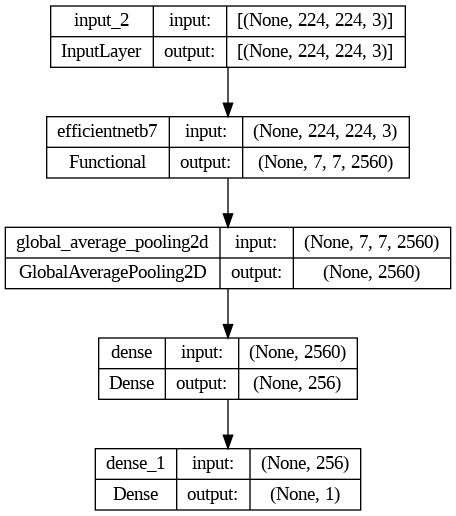

In [ ]:
from keras.utils import plot_model
plot_model(model, to_file=myModelsPath+myModelName+".png", show_shapes=True)

In [ ]:
history_base.history.keys()

dict_keys(['loss', 'binary_accuracy', 'auc', 'recall', 'precision', 'sensitivity_at_specificity', 'specificity_at_sensitivity', 'val_loss', 'val_binary_accuracy', 'val_auc', 'val_recall', 'val_precision', 'val_sensitivity_at_specificity', 'val_specificity_at_sensitivity'])

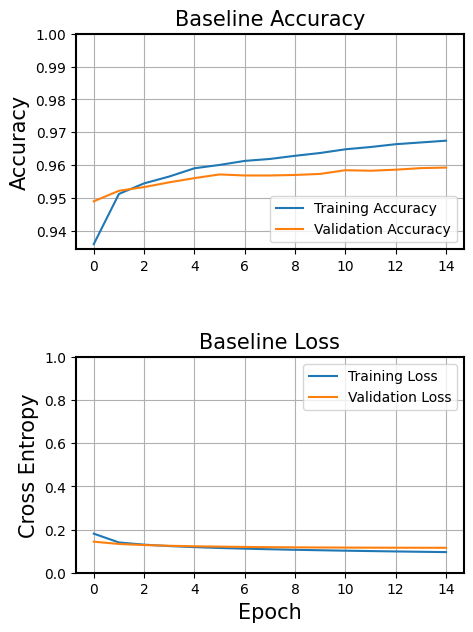

In [ ]:
if not(False):
  # Look at training performance
  acc = history_base.history['binary_accuracy']
  val_acc = history_base.history['val_binary_accuracy']

  loss = history_base.history['loss']
  val_loss = history_base.history['val_loss']

  plt.figure(figsize=(5, 7))
  plt.subplot(2, 1, 1)
  plt.grid()
  plt.plot(acc, label='Training Accuracy')
  plt.plot(val_acc, label='Validation Accuracy')
  plt.legend(loc='lower right')
  plt.ylabel('Accuracy')
  plt.ylim([min(plt.ylim()),1])
  plt.title('Baseline Accuracy')

  plt.subplot(2, 1, 2)
  plt.grid()
  plt.plot(loss, label='Training Loss')
  plt.plot(val_loss, label='Validation Loss')
  plt.legend(loc='upper right')
  plt.ylabel('Cross Entropy')
  plt.ylim([0,1.0])
  plt.title('Baseline Loss')
  plt.xlabel('Epoch')
  plt.subplots_adjust(wspace=0, hspace=0.5)
  plt.show()

### Save the model

We can save a model with `keras.models.save_model()`. We can load it back with `keras.models.load_model()`.


####We can't find a way to save this model

This may have to do with mixing tf.keras functions and kera functions earlier in the code. No time to re-run everything now.

In [ ]:
myModelName = "EfficientNetB7_v0"
if(SAVE_MODEL):
   keras.models.save_model(model, myModelsPath + myModelName , overwrite=True)  # throws error

  # Load the base model for comparison
  # base_model = tf.keras.models.load_model(myModelsPath + "BaseModel_ThreeEpochs") # save from a previous run

FailedPreconditionError: ignored

In [ ]:
# myModelName = "EfficientNetB7_v0"
# if(SAVE_MODEL):
#   keras.models.save_weights(model.weights, myModelsPath + myModelName + ".h5") # throws error

#   # Load the base model for comparison
#   base_model = tf.keras.models.load_model(myModelsPath + myModelName+"_folder")
#   base_model.load_weights(myModelsPath + myModelName + ".h5")

In [ ]:
# import pickle
# myFile = myModelsPath + myModelName + ".sav"
# pickle.dump(model, open(myFile, 'wb'))

# loaded_model = pickle.load(open(myFile, 'rb'))
# np.testing.assert_allclose(
#     model.predict(test_dataset), loaded_model.predict(test_dataset.astype('float32')) # throws error
# )

## Evaluate the Model with Test dataset

In [ ]:
# Collect the labels
#train_labels = np.concatenate([y for x, y in train_dataset], axis=0)
#pd.value_counts(train_labels.tolist())

#validation_labels = np.concatenate([y for x, y in validation_dataset], axis=0)
#pd.value_counts(validation_labels.tolist())

test_labels = np.concatenate([y for x, y in test_dataset], axis=0)
pd.value_counts(test_labels.tolist())

[0.0]    1300
[1.0]    1300
dtype: int64

In [ ]:
# print performance
result_test = model.evaluate(test_dataset)
test_perf = dict(zip(model.metrics_names, result_test))
#print(test_perf)


82/82 [==============================] - 203s 2s/step - loss: 0.1281 - binary_accuracy: 0.9562 - auc: 0.9892 - recall: 0.9600 - precision: 0.9527 - sensitivity_at_specificity: 0.9608 - specificity_at_sensitivity: 0.9638


from sklearn.metrics import roc_curve

fpr,tpr,thresholds=roc_curve(y_test,y_pred_prob)

In [ ]:
y_pred = model.predict(test_dataset)


82/82 [==============================] - 198s 2s/step


In [ ]:
# To find the knee in the ROC curve, we find the point on the line tpr = 1 - fpr where it intersects
# with the ROC curve given fpr and tpr and thresholds. This corresponds to Youden's J statistic.
# This is one way to select an optimal tradeoff between sensitivity and specificity.

def find_threshold(fpr, tpr, thresholds):
  """Finds the threshold that maximizes the Youden's J statistic.

  The Youden's J statistic is a measure of the overall performance of a
  classification model. It is defined as the sensitivity (tpr) minus the
  false positive rate (fpr).

  Args:
    fpr: A numpy array of false positive rates.
    tpr: A numpy array of true positive rates.
    thresholds: A numpy array of thresholds.

  Returns: th_opt, indx_opt
    th_opt: A float representing the threshold that maximizes the Youden's J statistic.
    indx_opt: An integer representing the index of the threshold that maximizes the Youden's J statistic.
  """

  j_scores = tpr - fpr
  th = thresholds[np.argmax(j_scores)]
  indx = np.where(thresholds == th)
  return th, indx[0][0]


Optimal threshold: 0.6129955053329468


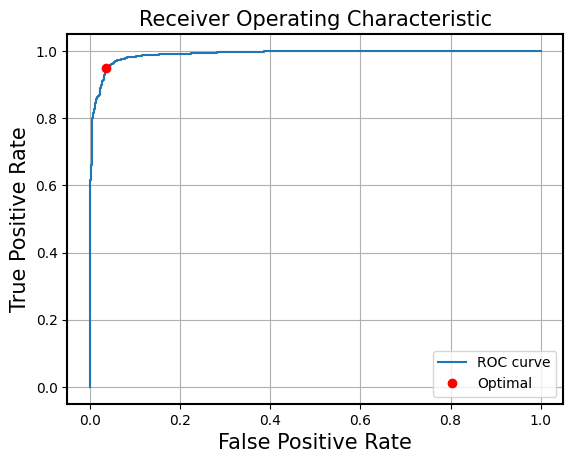

In [ ]:
# Produce a ROC curve from y_pred and test_labels

from sklearn.metrics import roc_curve, roc_auc_score
fpr,tpr,thresholds=roc_curve(test_labels, y_pred)
th_opt, opt_indx = find_threshold(fpr, tpr, thresholds)
print(f"Optimal threshold: {th_opt}")

plt.plot(fpr,tpr,label="ROC curve")
plt.plot(fpr[opt_indx],tpr[opt_indx],'ro',label="Optimal")
plt.title('Receiver Operating Characteristic')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.grid()
plt.show()


In [ ]:
test_perf.keys()

dict_keys(['loss', 'binary_accuracy', 'auc', 'recall', 'precision', 'sensitivity_at_specificity', 'specificity_at_sensitivity'])

In [ ]:
# Get the area under the ROC curve using test_labels and y_pred

auc = roc_auc_score(test_labels, y_pred)
print(f"Test performance binary_accuracy: {test_perf['binary_accuracy']:.2f}")
print(f"Area under the ROC curve: {auc:.2f}")
print(f"Optimal threshold: {th_opt:.2f}")
print(f"Optimal threshold index: {opt_indx}")
print(f"Optimal Sensitivity (tpr): {tpr[opt_indx]:.2f}")
print(f"Optimal Specificity (1-fpr): {1-fpr[opt_indx]:.2f}")
print(f"Test performance recall: {test_perf['recall']:.2f}")
print(f"Test performance precision: {test_perf['precision']:.2f}")
print(f"Test performance AUC: {test_perf['auc']:.2f}")
print(f"Test performance SensitivityAtSpecificity: {test_perf['sensitivity_at_specificity']:.2f}")
print(f"Test performance SpecificityAtSensitivity: {test_perf['specificity_at_sensitivity']:.2f}")

Test performance binary_accuracy: 0.96
Area under the ROC curve: 0.99
Optimal threshold: 0.61
Optimal threshold index: 86
Optimal Sensitivity (tpr): 0.95
Optimal Specificity (1-fpr): 0.96
Test performance recall: 0.96
Test performance precision: 0.95
Test performance AUC: 0.99
Test performance SensitivityAtSpecificity: 0.96
Test performance SpecificityAtSensitivity: 0.96


In [ ]:
myModelName

'EfficientNetB7_v0'

In [ ]:
def calculate_tp_fp_tn_fn(thresholds, test_labels, y_pred):
  """Calculates true positives, false positives, true negatives, and false negatives.

  Calculates the true positives, false positives, true negatives, and false negatives
  for each threshold in the thresholds array.

  Args:
    thresholds: A numpy array of thresholds.
    test_labels: A numpy array of test labels.
    y_pred: A numpy array of predicted labels.

  Returns:
    A tuple of numpy arrays containing the true positives, false positives, true negatives,
    and false negatives for each threshold.
  """

  tp = np.zeros_like(thresholds)
  fp = np.zeros_like(thresholds)
  tn = np.zeros_like(thresholds)
  fn = np.zeros_like(thresholds)

  for i, threshold in enumerate(thresholds):
    y_pred_binary = np.where(y_pred >= threshold, 1, 0)
    tp[i] = np.sum(np.logical_and(y_pred_binary == 1, test_labels == 1))
    fp[i] = np.sum(np.logical_and(y_pred_binary == 1, test_labels == 0))
    tn[i] = np.sum(np.logical_and(y_pred_binary == 0, test_labels == 0))
    fn[i] = np.sum(np.logical_and(y_pred_binary == 0, test_labels == 1))

  return int(tp), int(fp), int(tn), int(fn)


In [ ]:
def visualize_confusion_matrix(tp, fp, tn, fn):
  """Visualizes a confusion matrix.

  Visualizes a confusion matrix using Seaborn.

  Args:
    tp: A numpy array of true positives.
    fp: A numpy array of false positives.
    tn: A numpy array of true negatives.
    fn: A numpy array of false negatives.
  """

  cm = np.squeeze(np.array([[tp, fp], [fn, tn]]))
  sns.heatmap(cm, xticklabels=["Predicted Negative", "Predicted Positive"],
               yticklabels=["Actual Negative", "Actual Positive"],
              annot=True, cbar=False, fmt='d')
  plt.xlabel("Predicted Label")
  plt.ylabel("Actual Label")
  plt.title("Confusion Matrix")
  plt.show()



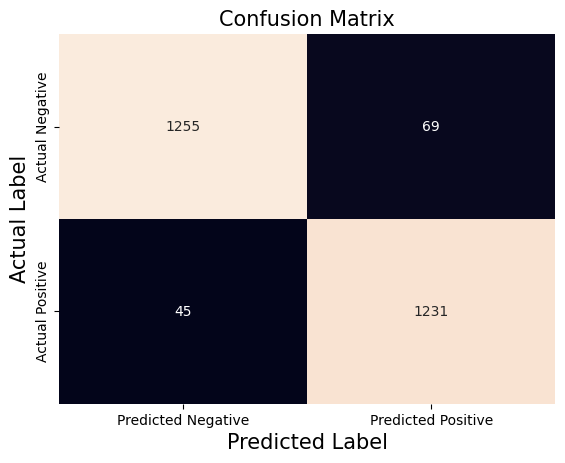

True positives: 1255
False positives: 69
True negatives: 1231
False negatives: 45
Accuracy: 0.96
Sensitivity (TPR): 0.97
Specificity (TNR): 0.95
Precision: 0.95
F1 score: 0.96


In [ ]:

# By lowering the optimal threshold, we can improve recall while maintaining an acceptable FPR.
tp, fp, tn, fn = calculate_tp_fp_tn_fn([0.4], test_labels, y_pred)
visualize_confusion_matrix(tp, fp, tn, fn)
print(f"True positives: {tp}")
print(f"False positives: {fp}")
print(f"True negatives: {tn}")
print(f"False negatives: {fn}")
print(f"Accuracy: {(tp + tn) / (tp + fp + tn + fn):.2f}")
print(f"Sensitivity (TPR): {tp / (tp + fn):.2f}")
print(f"Specificity (TNR): {tn / (tn + fp):.2f}")
print(f"Precision: {tp / (tp + fp):.2f}")
print(f"F1 score: {2 * tp / (2 * tp + fp + fn):.2f}")